# 🚀 Модуль 2. Урок 3. Глубокое погружение в JOIN: исключение дубликатов и декартова произведения

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_02_sql/lesson_03_joins_deep_dive.ipynb)

## 📌 Бизнес-контекст и методология
Связывание таблиц (`INNER`, `LEFT`, `RIGHT`, `FULL OUTER JOIN`) — ежедневная задача аналитика.
Самая опасная ошибка — возникновение **Fan-out (раздувания строк)** при объединении таблиц с отношением "многие-ко-многим". Если у клиента несколько заказов и несколько обращений в поддержку, некорректный JOIN перемножит строки (Cartesian Product), завысив выручку в разы!

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

db_path = ensure_dataset("ecommerce.db")
conn = sqlite3.connect(db_path)
print(f"🟢 Подключение к базе данных успешно установлено: {db_path}")

🟢 Подключение к базе данных успешно установлено: course\datasets\ecommerce.db


## 🔍 Разбор механики и демонстрация на реальных данных
Исследуем конверсию базы зарегистрированных клиентов в реальных покупателей:
- Клиенты с 0 заказов (зарегистрировались, но не купили)
- Клиенты с 1 заказом (разовая покупка)
- Повторные покупатели (2+ заказов)

In [2]:
# Демонстрация: LEFT JOIN для анализа активности всех пользователей
query_join = """
SELECT 
    c.customer_id,
    c.acquisition_channel,
    c.city,
    COUNT(o.order_id) as total_orders,
    COALESCE(SUM(oi.total_amount), 0) as total_spent
FROM customers c
LEFT JOIN orders o ON c.customer_id = o.customer_id AND o.status = 'Completed'
LEFT JOIN order_items oi ON o.order_id = oi.order_id
GROUP BY c.customer_id, c.acquisition_channel, c.city;
"""
df_customer_lifecycle = pd.read_sql_query(query_join, conn)
print(f"Всего клиентов в базе: {len(df_customer_lifecycle)}")
display(df_customer_lifecycle.head(6))

Всего клиентов в базе: 1200


,customer_id,acquisition_channel,city,total_orders,total_spent
0,1,Organic Search,Moscow,4,3911.81
1,2,Social Media,Samara,1,843.33
2,3,Organic Search,Saint Petersburg,0,0.00
3,4,Direct,Yekaterinburg,8,8949.36
4,5,Social Media,Novosibirsk,1,1072.23
5,6,Direct,Novosibirsk,2,1583.36


## 📊 Визуализация бизнес-кейса: Жизненный цикл клиентов по каналам
Сравним каналы по качеству привлекаемой аудитории: какая доля пользователей застревает на стадии 0 заказов, а какая конвертируется в лояльных клиентов.

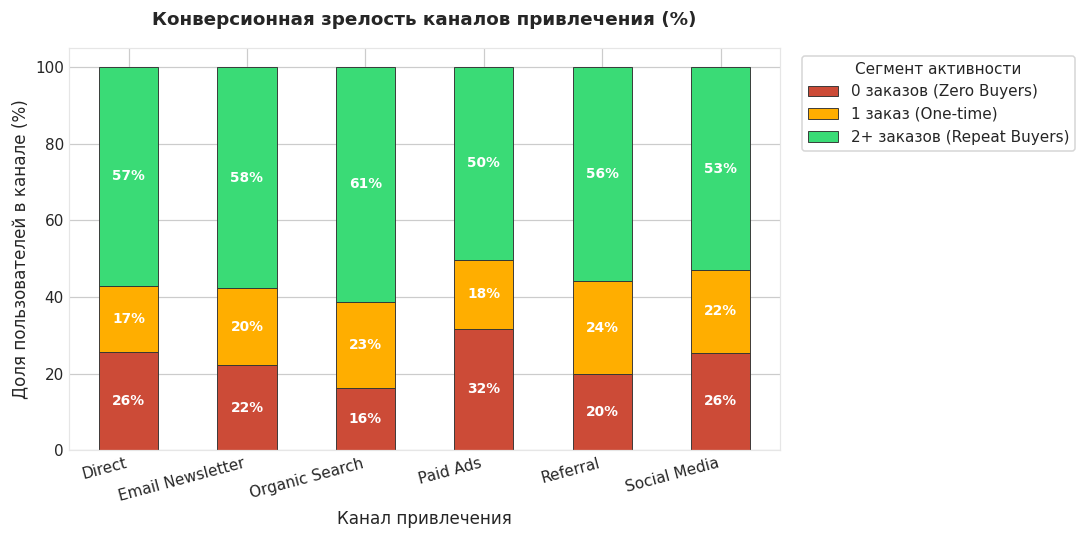

In [3]:
# Классификация жизненного цикла клиентов
def classify_user(orders):
    if orders == 0:
        return '0 заказов (Zero Buyers)'
    elif orders == 1:
        return '1 заказ (One-time)'
    else:
        return '2+ заказов (Repeat Buyers)'

df_customer_lifecycle['segment'] = df_customer_lifecycle['total_orders'].apply(classify_user)

seg_channel = df_customer_lifecycle.groupby(['acquisition_channel', 'segment']).size().unstack(fill_value=0)
seg_channel_pct = seg_channel.div(seg_channel.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5), dpi=110)
colors = [ALERT, WARNING, SUCCESS]

seg_channel_pct.plot(kind='bar', stacked=True, color=colors, ax=ax, edgecolor='#333333', linewidth=0.6)

ax.set_title("Конверсионная зрелость каналов привлечения (%)", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Доля пользователей в канале (%)", fontsize=11)
ax.set_xlabel("Канал привлечения", fontsize=11)
ax.set_xticklabels(seg_channel_pct.index, rotation=15, ha='right')
ax.legend(title="Сегмент активности", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

for c in ax.containers:
    labels = [f"{v:.0f}%" if v > 8 else "" for v in c.datavalues]
    ax.bar_label(c, labels=labels, label_type='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск клиентов без заказов
Используя `LEFT JOIN`, найдите клиентов, которые ни разу не оформили ни одного заказа (где `order_id IS NULL`).

In [4]:
### ВАШ КОД ЗДЕСЬ
query_no_orders = """
SELECT 
    c.customer_id,
    c.first_name,
    c.city,
    c.acquisition_channel
FROM customers c
LEFT JOIN orders o ON c.customer_id = o.customer_id
WHERE o.order_id IS NULL;
"""

df_no_orders = pd.read_sql_query(query_no_orders, conn)
print(f"Клиентов без совершенных заказов: {len(df_no_orders)}")
display(df_no_orders.head(5))

assert not df_no_orders.empty, "Должны быть клиенты без заказов"
print("✅ Тест успешно пройден: LEFT JOIN с отбором NULL строк работает безошибочно!")

Клиентов без совершенных заказов: 232


,customer_id,first_name,city,acquisition_channel
0,3,User_3,Saint Petersburg,Organic Search
1,7,User_7,Moscow,Referral
2,18,User_18,Kazan,Social Media
3,23,User_23,Kazan,Organic Search
4,26,User_26,Moscow,Direct


✅ Тест успешно пройден: LEFT JOIN с отбором NULL строк работает безошибочно!


### 💡 Архитектурный закон JOIN
1. Если при `LEFT JOIN` количество строк результирующей таблицы превысило размер левой таблицы, значит в правой таблице ключ объединения **не уникален** (связь «один-ко-многим»).
2. Для расчета денежных метрик всегда агрегируйте дочернюю таблицу перед объединением или используйте `COUNT(DISTINCT ...)`, чтобы не завысить выручку.